In [38]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as scipy
import pandas as pd

In [39]:
#Parameters
U = 1 #m/s

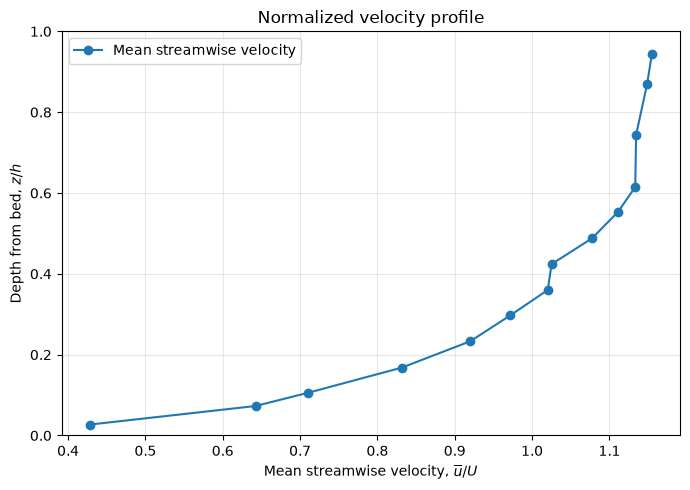

,z_over_h,u_mean,u_std
0,0.027,0.428011,0.118518
1,0.073,0.642520,0.151473
2,0.106,0.710852,0.153622
3,0.168,0.831580,0.149788
4,0.233,0.919850,0.141051
5,0.297,0.971665,0.135807
6,0.360,1.020204,0.120137
7,0.424,1.025218,0.119810
8,0.488,1.077534,0.110077
9,0.553,1.110985,0.098616


In [40]:
from pathlib import Path

# Each file is one measurement point; its name gives z/h in percent.
data_dir = Path("Velocity files for FSI")
profiles = []

for data_file in sorted(data_dir.glob("Z_*.dat"), key=lambda path: float(path.stem.split("_")[1])):
    z_over_h = float(data_file.stem.split("_")[1]) / 100
    data = np.loadtxt(data_file)
    profiles.append({
        "z_over_h": z_over_h,
        "u_mean": data[:, 1].mean(),
        "u_std": data[:, 1].std(ddof=1),
    })

profiles = pd.DataFrame(profiles).sort_values("z_over_h")

fig, ax = plt.subplots(figsize=(7, 5))
ax.errorbar(
    profiles["u_mean"],
    profiles["z_over_h"],
    # xerr=profiles["u_std"],
    fmt="o-",
    capsize=3,
    label="Mean streamwise velocity",
)
ax.set_xlabel(r"Mean streamwise velocity, $\overline{u}/U$")
ax.set_ylabel(r"Depth from bed, $z/h$")
ax.set_title("Normalized velocity profile")
ax.set_ylim(0, 1)
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
Path("figures").mkdir(exist_ok=True)
fig.savefig("figures/normalized_velocity_profile.png", dpi=300, bbox_inches="tight")
plt.show()

profiles

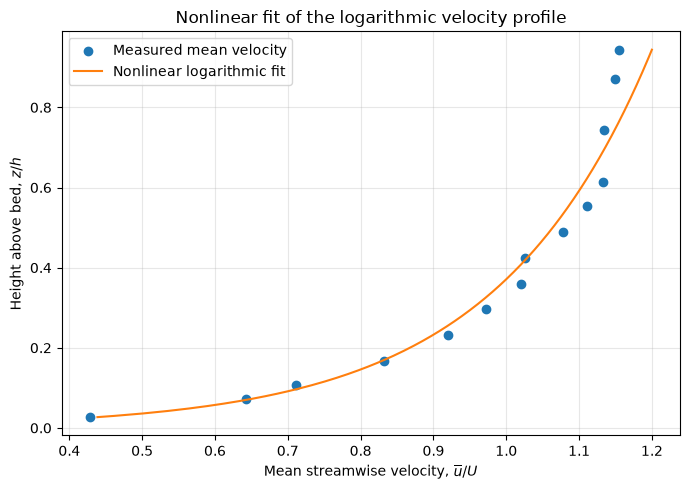

u* = 0.08782
z0/h = 0.00348
roughness height ks/h = 30 z0/h = 0.10452
sum of squared residuals = 0.007140


In [ ]:
from scipy.optimize import least_squares

kappa = 0.41
z_data = profiles["z_over_h"].to_numpy()
u_data = profiles["u_mean"].to_numpy()

def log_law(params, z):
    u_star_over_U, z0_over_h = params
    return u_star_over_U / kappa * np.log(z / z0_over_h)

fit = least_squares(
    lambda params: log_law(params, z_data) - u_data,
    x0=[0.1, 0.001],
    bounds=([1e-8, 1e-8], [np.inf, z_data.min() * 0.999]),
)
u_star_over_U, z0_over_h = fit.x
roughness_over_h = 30 * z0_over_h

z_fit = np.linspace(z_data.min(), z_data.max(), 300)
u_fit = log_law(fit.x, z_fit)

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(u_data, z_data, color="tab:blue", label="Measured mean velocity")
ax.plot(
    u_fit,
    z_fit,
    color="tab:orange",
    label="Nonlinear logarithmic fit",
)
ax.set_xlabel(r"Mean streamwise velocity, $\overline{u}/U$")
ax.set_ylabel(r"Height above bed, $z/h$")
ax.set_title("Nonlinear fit of the logarithmic velocity profile")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig("figures/nonlinear_fit_of_the_logarithmic_velocity_profile.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"u* = {u_star_over_U * U:.5f}")
print(f"z0/h = {z0_over_h:.5f}")
print(f"roughness height ks/h = 30 z0/h = {roughness_over_h:.5f}")
print(f"sum of squared residuals = {2 * fit.cost:.6f}")

In [42]:
rho = 1000.0  # kg/m^3, water

u_star = u_star_over_U * U
tau_b = rho * u_star**2

print(f"Average velocity U = {U:.5f} m/s")
print(f"Shear velocity u* = {u_star:.5f} m/s")
print(f"Bed shear stress tau_b = {tau_b:.5f} Pa")

Average velocity U = 1.00000 m/s
Shear velocity u* = 0.08782 m/s
Bed shear stress tau_b = 7.71282 Pa


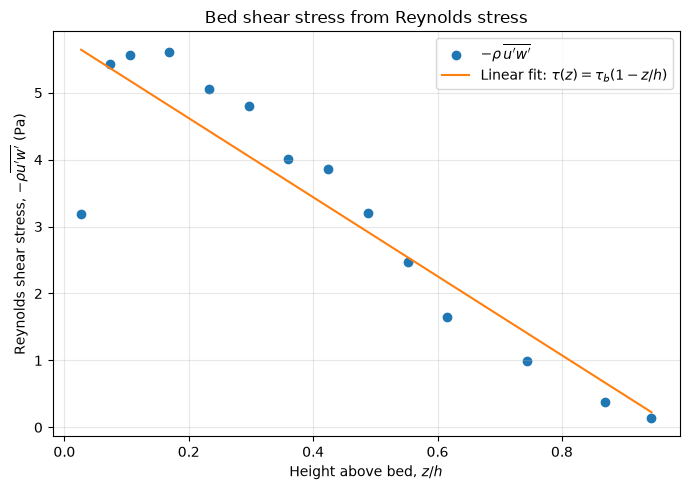

Bed shear stress from Reynolds-stress extrapolation = 5.80209 Pa
Linear stress slope = -5.90706 Pa per unit z/h


In [43]:
rho = 1000.0  # kg/m^3, water
z_fit = np.linspace(z_data.min(), z_data.max(), 300)

reynolds_stress = []
for data_file in sorted(data_dir.glob("Z_*.dat"), key=lambda path: float(path.stem.split("_")[1])):
    z_over_h = float(data_file.stem.split("_")[1]) / 100
    data = np.loadtxt(data_file)
    u_fluctuation = data[:, 1] - data[:, 1].mean()
    w_fluctuation = data[:, 2] - data[:, 2].mean()
    covariance_normalized = np.mean(u_fluctuation * w_fluctuation)
    reynolds_stress.append({
        "z_over_h": z_over_h,
        "tau_reynolds": -rho * U**2 * covariance_normalized,
    })

reynolds_stress = pd.DataFrame(reynolds_stress).sort_values("z_over_h")
stress_slope, tau_b_reynolds = np.polyfit(
    reynolds_stress["z_over_h"],
    reynolds_stress["tau_reynolds"],
    1,
)
stress_fit = tau_b_reynolds + stress_slope * z_fit

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(
    reynolds_stress["z_over_h"],
    reynolds_stress["tau_reynolds"],
    color="tab:blue",
    label=r"$-\rho\,\overline{u'w'}$",
)
ax.plot(
    z_fit,
    stress_fit,
    color="tab:orange",
    label=r"Linear fit: $\tau(z)=\tau_b(1-z/h)$",
)
ax.set_xlabel(r"Height above bed, $z/h$")
ax.set_ylabel(r"Reynolds shear stress, $-\rho\overline{u'w'}$ (Pa)")
ax.set_title("Bed shear stress from Reynolds stress")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig("figures/bed_shear_stress_from_reynolds_stress.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"Bed shear stress from Reynolds-stress extrapolation = {tau_b_reynolds:.5f} Pa")
print(f"Linear stress slope = {stress_slope:.5f} Pa per unit z/h")